# Mini-Project 1 — Advanced Python Data Exploration & Automated Reporting

This notebook documents the complete workflow required by the project: loading, cleaning, validation, feature engineering, EDA, statistics, visualizations, KPI reporting, reusable functions, OOP, exception handling, export, and memory optimization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print('Everything is working!')
df = pd.read_excel('Sales Data.xlsx', sheet_name='Sales Data')
print('File loaded successfully!')
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
print('\nColumn Names:')
for i, col in enumerate(df.columns):
    print(i, ':', col)
print('\nData Types:')
print(df.dtypes)
df.info()


Everything is working!
File loaded successfully!
Rows: 1008
Columns: 83

Column Names:
0 : Order ID
1 : Year
2 : Month
3 : Order Date
4 : Ship Date
5 : Ship Mode
6 : Customer ID
7 : Customer Name
8 : Client Segment
9 : Country
10 : State
11 : Postal Code
12 : Region
13 : Product ID
14 : Product Category
15 : Sub-Category
16 : Product Name
17 : Sales Price
18 : Quantity
19 : Discount
20 : Total Sales Amount
21 : Purchasing Price
22 : Total Purchasing Amounts
23 : Net Profit
24 : Unnamed: 24
25 : Unnamed: 25
26 : Unnamed: 26
27 : Unnamed: 27
28 : Unnamed: 28
29 : Unnamed: 29
30 : Unnamed: 30
31 : Unnamed: 31
32 : Unnamed: 32
33 : Unnamed: 33
34 : Unnamed: 34
35 : Unnamed: 35
36 : Unnamed: 36
37 : Unnamed: 37
38 : Unnamed: 38
39 : Unnamed: 39
40 : Unnamed: 40
41 : Unnamed: 41
42 : Unnamed: 42
43 : Unnamed: 43
44 : Unnamed: 44
45 : Unnamed: 45
46 : Unnamed: 46
47 : Unnamed: 47
48 : Unnamed: 48
49 : Unnamed: 49
50 : Unnamed: 50
51 : Unnamed: 51
52 : Unnamed: 52
53 : Unnamed: 53
54 : Unnamed

## 1. Data Cleaning & Validation

Remove unnecessary columns and empty rows, standardize dates/types, inspect duplicates and ranges, validate Year, discounts, sales, purchasing, profit, and detect outliers.

In [2]:
unnamed_columns = df.columns[df.columns.str.startswith('Unnamed')]
print('Number of Unnamed columns:', len(unnamed_columns))

df = df.iloc[:, :24].copy()
df = df.dropna(how='all').reset_index(drop=True)
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Year'] = df['Year'].astype(int)
df['Quantity'] = df['Quantity'].astype(int)

print('Rows after cleaning:', len(df))
print('Columns after cleaning:', len(df.columns))
print('Duplicate rows:', df.duplicated().sum())
print('\nMissing values:')
print(df.isnull().sum())

print('\nNumeric ranges:')
for col in ['Year','Quantity','Discount','Sales Price','Net Profit']:
    print(col, ':', df[col].min(), 'to', df[col].max())

# Year validation
df['Order_Date_Year'] = df['Order Date'].dt.year
wrong_year = df[df['Year'] != df['Order_Date_Year']]
print('\nInconsistent Year values:', len(wrong_year))
df['Year'] = df['Order Date'].dt.year

# Outlier detection using IQR
numeric_columns = ['Sales Price','Quantity','Total Sales Amount','Purchasing Price','Total Purchasing Amounts','Net Profit']
for col in numeric_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col}: {count} outliers')

# Sales and purchasing validation
df['Expected Sales'] = df['Sales Price'] * df['Quantity']
df['Expected Purchasing'] = df['Purchasing Price'] * df['Quantity']
df['Sales Difference'] = df['Total Sales Amount'] - df['Expected Sales']
df['Purchasing Difference'] = df['Total Purchasing Amounts'] - df['Expected Purchasing']
print('\nMaximum Sales Difference:', df['Sales Difference'].abs().max())
print('Maximum Purchasing Difference:', df['Purchasing Difference'].abs().max())
print('Sales calculation errors:', (df['Sales Difference'].abs() > 0.01).sum())

# Discount validation
df['Calculated_Discount'] = (1 - df['Total Sales Amount'] / df['Expected Sales']).round(4)
df['Original_Discount'] = df['Discount']
df['Discount'] = df['Calculated_Discount']
print('\nActual discount rates:')
print(df['Calculated_Discount'].value_counts().sort_index())

# Profit validation
df['Expected_Profit'] = df['Total Sales Amount'] - df['Total Purchasing Amounts']
df['Profit_Difference'] = df['Net Profit'] - df['Expected_Profit']
print('\nMaximum Profit Difference:', df['Profit_Difference'].abs().max())
print('Profit calculation errors:', (df['Profit_Difference'].abs() > 0.01).sum())

temporary = ['Expected Sales','Expected Purchasing','Sales Difference','Purchasing Difference','Calculated_Discount','Original_Discount','Expected_Profit','Profit_Difference','Order_Date_Year']
df.drop(columns=temporary, inplace=True)


Number of Unnamed columns: 59
Rows after cleaning: 1007
Columns after cleaning: 24
Duplicate rows: 0

Missing values:
Order ID                    0
Year                        0
Month                       0
Order Date                  0
Ship Date                   0
Ship Mode                   0
Customer ID                 0
Customer Name               0
Client Segment              0
Country                     0
State                       0
Postal Code                 0
Region                      0
Product ID                  0
Product Category            0
Sub-Category                0
Product Name                0
Sales Price                 0
Quantity                    0
Discount                    0
Total Sales Amount          0
Purchasing Price            0
Total Purchasing Amounts    0
Net Profit                  0
dtype: int64

Numeric ranges:
Year : 2014 to 2020
Quantity : 1 to 14
Discount : 0.0 to 0.0
Sales Price : 1.0800000000000003 to 8159.951999999999
Net Profit : 0.52

## 2. Feature Engineering

In [3]:
df['Profit Margin'] = (df['Net Profit'] / df['Total Sales Amount']) * 100
df['Shipping Duration'] = (df['Ship Date'] - df['Order Date']).dt.days

def classify_performance(margin):
    if margin >= 40:
        return 'High'
    elif margin >= 20:
        return 'Medium'
    return 'Low'

df['Sales Performance Category'] = df['Profit Margin'].apply(classify_performance)
print(df[['Profit Margin','Shipping Duration','Sales Performance Category']].head())


   Profit Margin  Shipping Duration Sales Performance Category
0           40.0                  3                       High
1           45.0                  3                       High
2           40.0                  4                       High
3           50.0                  7                       High
4           37.5                  7                     Medium


## 3. Business Analysis / EDA

In [4]:
annual_analysis = df.groupby('Year').agg({'Total Sales Amount':'sum','Net Profit':'sum'}).reset_index()
category_analysis = df.groupby('Product Category').agg({'Total Sales Amount':'sum','Net Profit':'sum','Quantity':'sum'}).reset_index()
region_analysis = df.groupby('Region').agg({'Total Sales Amount':'sum','Net Profit':'sum'}).reset_index()
segment_analysis = df.groupby('Client Segment').agg({'Total Sales Amount':'sum','Net Profit':'sum','Quantity':'sum'}).reset_index()
performance_analysis = df.groupby('Sales Performance Category').agg({'Total Sales Amount':'sum','Net Profit':'sum','Quantity':'sum'}).reset_index()

print('Annual Analysis:\n', annual_analysis)
print('\nProduct Category Analysis:\n', category_analysis)
print('\nRegion Analysis:\n', region_analysis)
print('\nClient Segment Analysis:\n', segment_analysis)
print('\nSales Performance Analysis:\n', performance_analysis)


Annual Analysis:
    Year  Total Sales Amount     Net Profit
0  2014       323177.923300  108999.604850
1  2015       261186.185600   91378.607550
2  2016       286503.791132  102445.659972
3  2017       251243.931208   90876.638858

Product Category Analysis:
   Product Category  Total Sales Amount    Net Profit  Quantity
0        Furniture        350229.84414  113917.37838       792
1  Office Supplies        308966.08340  109072.46020      2297
2       Technology        462915.90370  170710.67265       749

Region Analysis:
     Region  Total Sales Amount    Net Profit
0  Central        313855.48734  105269.82288
1     East        286321.20610  101024.99755
2    South        180778.21970   69639.69905
3     West        341156.91810  117765.99175

Client Segment Analysis:
   Client Segment  Total Sales Amount    Net Profit  Quantity
0       Consumer        597162.22569  203984.18358      2086
1      Corporate        305427.90100  114791.07005      1097
2    Home Office        219521.7

## 4. Visualizations — 8 Required Figures

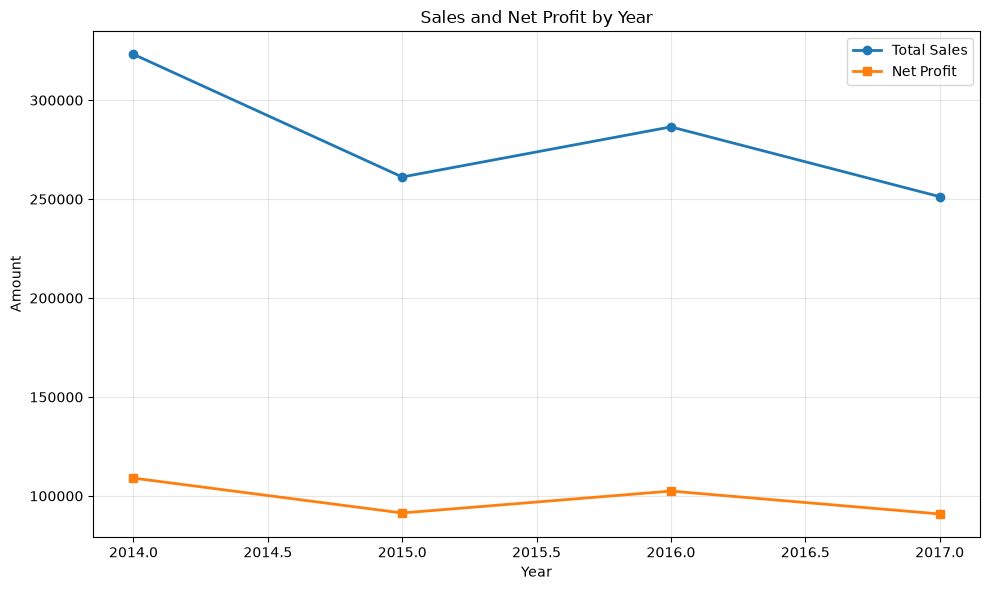

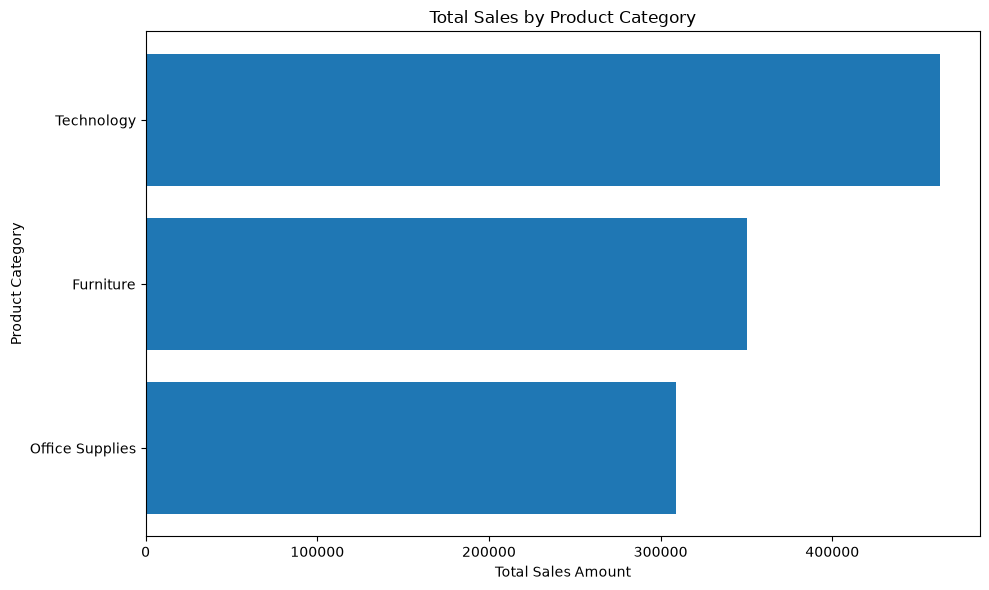

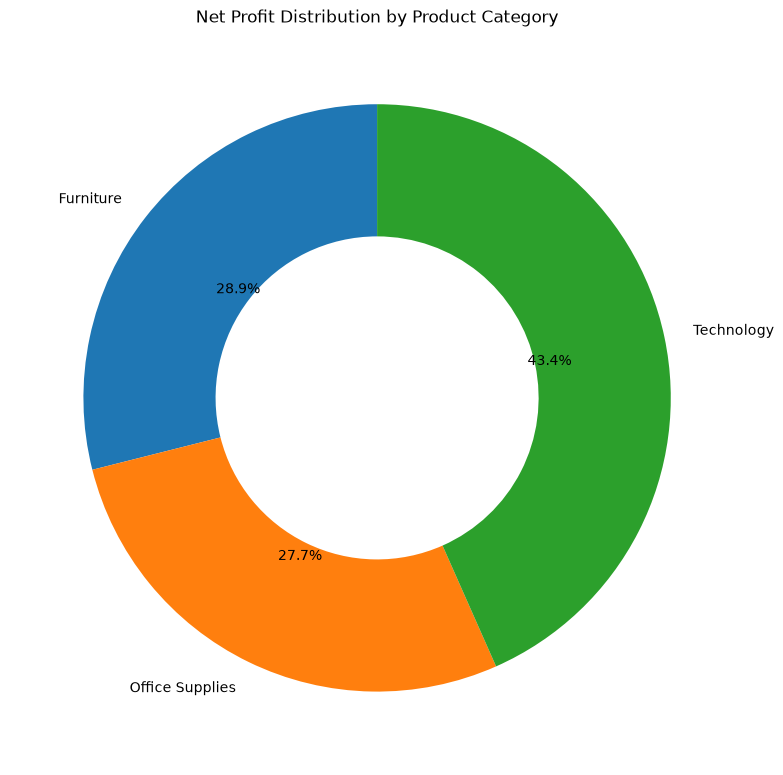

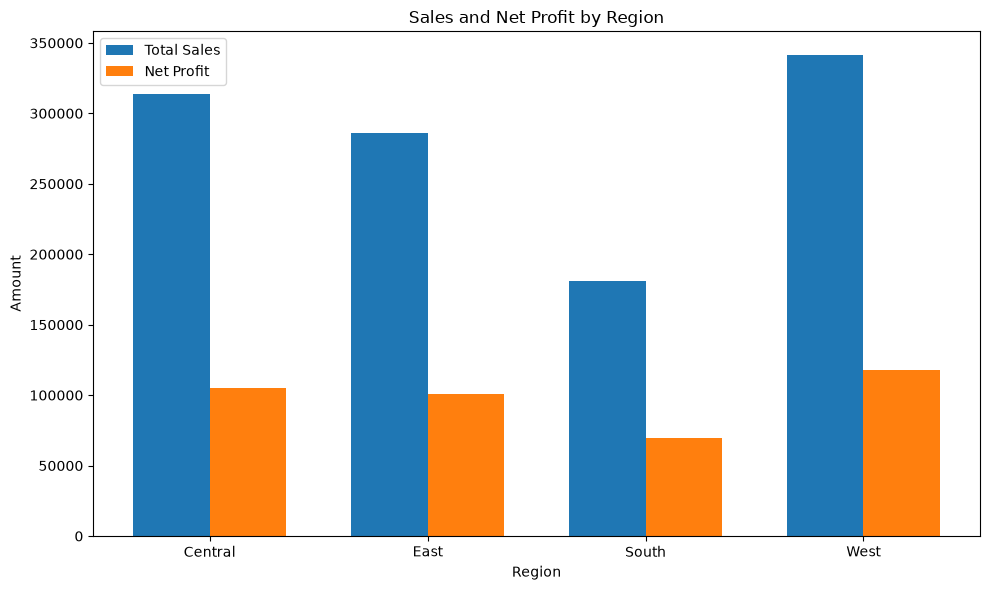

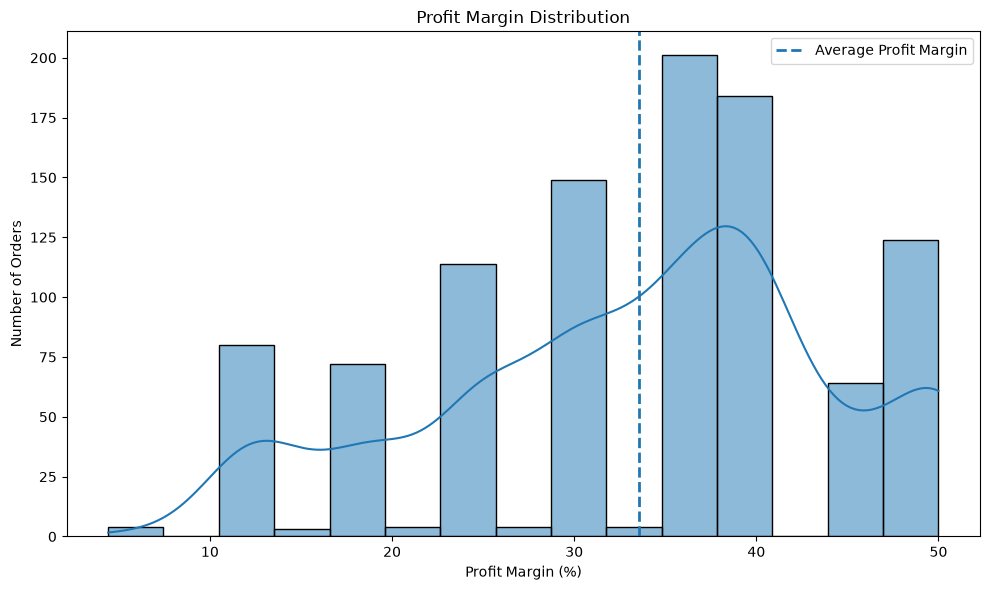

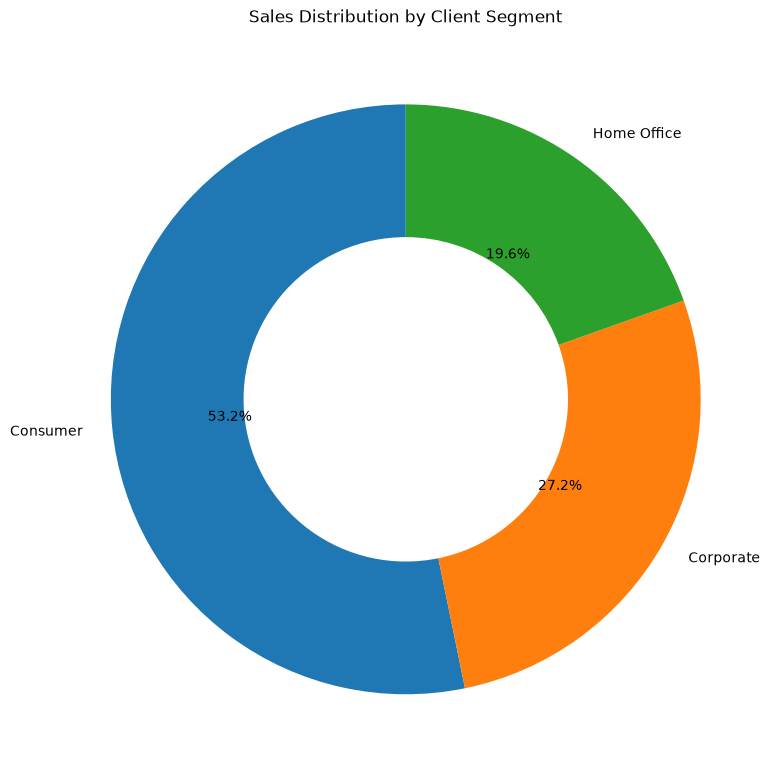

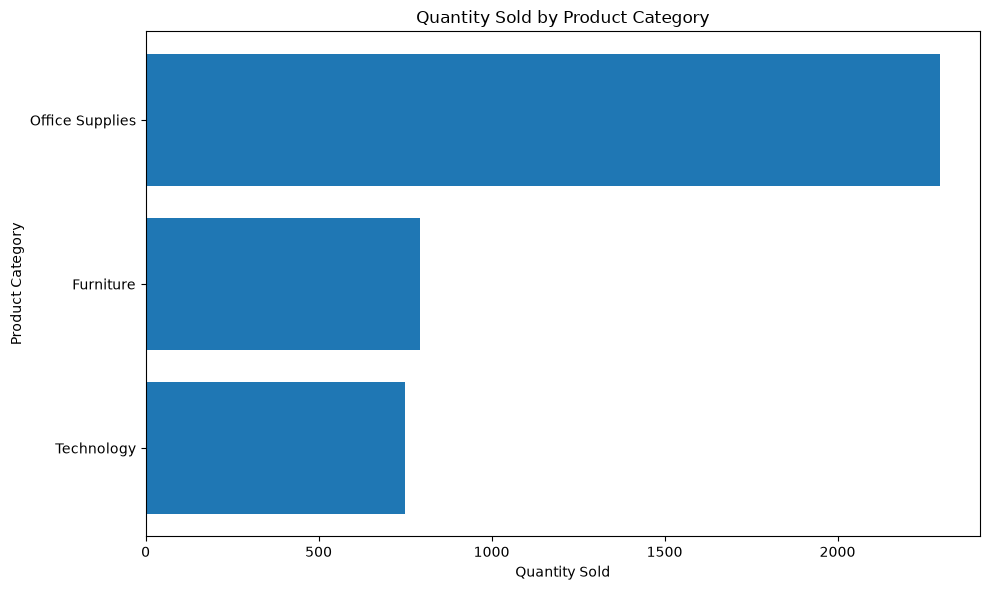

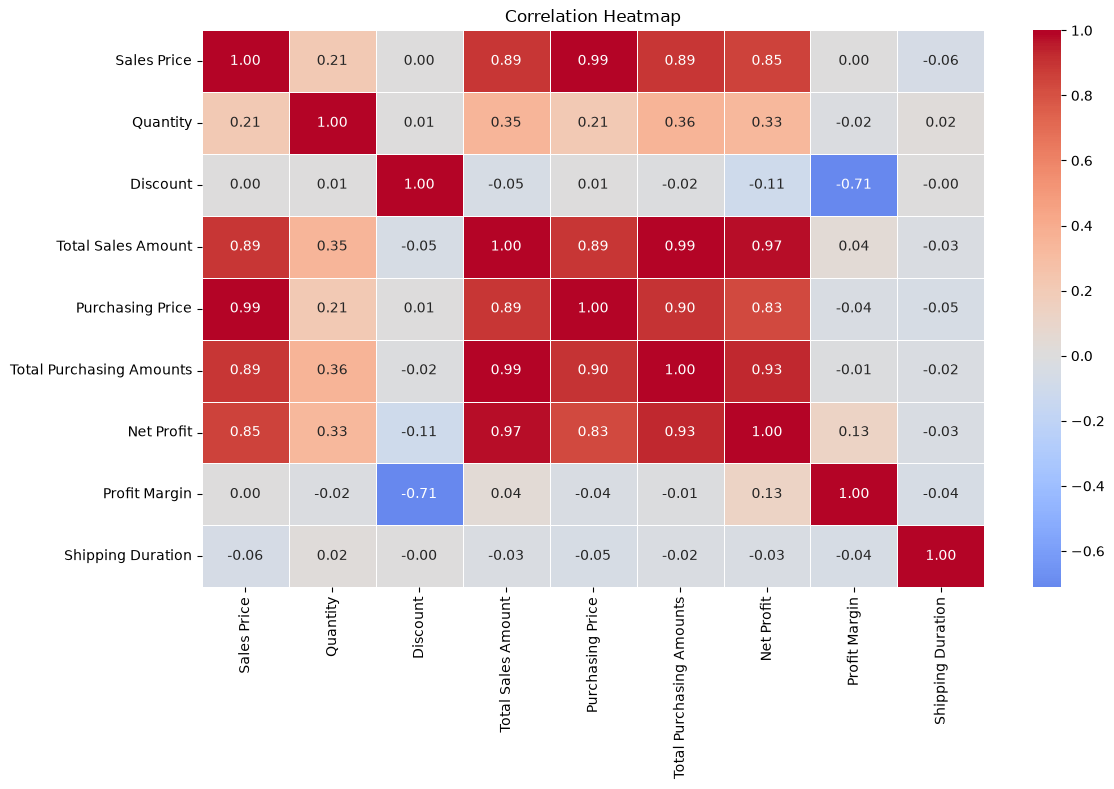


All 8 visualizations created and exported successfully!


In [20]:
# ============================================================
# 12. VISUALIZATIONS
# ============================================================


# ============================================================
# Visualization 1: Sales and Net Profit by Year
# Line Chart
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    annual_analysis["Year"],
    annual_analysis["Total Sales Amount"],
    marker="o",
    linewidth=2,
    label="Total Sales"
)

plt.plot(
    annual_analysis["Year"],
    annual_analysis["Net Profit"],
    marker="s",
    linewidth=2,
    label="Net Profit"
)

plt.title("Sales and Net Profit by Year")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "01_sales_profit_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Visualization 2: Sales by Product Category
# Horizontal Bar Chart
# ============================================================

category_sales = category_analysis.sort_values(
    "Total Sales Amount",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_sales["Product Category"],
    category_sales["Total Sales Amount"]
)

plt.title("Total Sales by Product Category")
plt.xlabel("Total Sales Amount")
plt.ylabel("Product Category")

plt.tight_layout()

plt.savefig(
    "02_sales_by_product_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Visualization 3: Net Profit by Product Category
# Donut Chart
# ============================================================

plt.figure(figsize=(8, 8))

plt.pie(
    category_analysis["Net Profit"],
    labels=category_analysis["Product Category"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45}
)

plt.title("Net Profit Distribution by Product Category")

plt.tight_layout()

plt.savefig(
    "03_profit_by_product_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Visualization 4: Regional Sales - Clustered Column Chart

x = np.arange(len(region_analysis["Region"]))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    region_analysis["Total Sales Amount"],
    width,
    label="Total Sales"
)

plt.bar(
    x + width/2,
    region_analysis["Net Profit"],
    width,
    label="Net Profit"
)

plt.title("Sales and Net Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")

plt.xticks(
    x,
    region_analysis["Region"]
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "04_sales_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# Visualization 5: Profit Margin Distribution
# Histogram + KDE
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    df["Profit Margin"],
    bins=15,
    kde=True
)

plt.axvline(
    df["Profit Margin"].mean(),
    linestyle="--",
    linewidth=2,
    label="Average Profit Margin"
)

plt.title("Profit Margin Distribution")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Number of Orders")
plt.legend()

plt.tight_layout()

plt.savefig(
    "05_profit_margin_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Visualization 6: Sales by Client Segment
# Donut Chart
# ============================================================

plt.figure(figsize=(8, 8))

plt.pie(
    segment_analysis["Total Sales Amount"],
    labels=segment_analysis["Client Segment"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45}
)

plt.title("Sales Distribution by Client Segment")

plt.tight_layout()

plt.savefig(
    "06_sales_by_client_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Visualization 7: Quantity Sold by Product Category
# Horizontal Bar Chart
# ============================================================

category_quantity = category_analysis.sort_values(
    "Quantity",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_quantity["Product Category"],
    category_quantity["Quantity"]
)

plt.title("Quantity Sold by Product Category")
plt.xlabel("Quantity Sold")
plt.ylabel("Product Category")

plt.tight_layout()

plt.savefig(
    "07_quantity_by_product_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Visualization 8: Correlation Heatmap
# ============================================================

correlation_columns = [
    "Sales Price",
    "Quantity",
    "Discount",
    "Total Sales Amount",
    "Purchasing Price",
    "Total Purchasing Amounts",
    "Net Profit",
    "Profit Margin",
    "Shipping Duration"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    "08_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nAll 8 visualizations created and exported successfully!")


## 5. Statistical Analysis

In [6]:
correlation_pairs = correlation_matrix.unstack()
correlation_pairs = correlation_pairs[correlation_pairs.index.get_level_values(0) != correlation_pairs.index.get_level_values(1)]
correlation_pairs = correlation_pairs.sort_values(ascending=False)
print('Strongest Positive Correlations:')
print(correlation_pairs.head(10))


Strongest Positive Correlations:
Sales Price               Purchasing Price            0.991156
Purchasing Price          Sales Price                 0.991156
Total Sales Amount        Total Purchasing Amounts    0.989712
Total Purchasing Amounts  Total Sales Amount          0.989712
Total Sales Amount        Net Profit                  0.973856
Net Profit                Total Sales Amount          0.973856
                          Total Purchasing Amounts    0.931334
Total Purchasing Amounts  Net Profit                  0.931334
                          Purchasing Price            0.902974
Purchasing Price          Total Purchasing Amounts    0.902974
dtype: float64


## 6. Automated KPI Summary

In [7]:
total_sales = df['Total Sales Amount'].sum()
total_cost = df['Total Purchasing Amounts'].sum()
total_profit = df['Net Profit'].sum()
total_quantity = df['Quantity'].sum()
overall_profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / df['Order ID'].nunique()

print('='*50)
print('SALES ANALYTICAL KPI REPORT')
print('='*50)
print(f'Total Sales:           {total_sales:,.2f}')
print(f'Total Purchasing Cost: {total_cost:,.2f}')
print(f'Total Net Profit:      {total_profit:,.2f}')
print(f'Total Quantity Sold:   {total_quantity:,}')
print(f'Overall Profit Margin: {overall_profit_margin:.2f}%')
print(f'Number of Orders:      {df["Order ID"].nunique():,}')
print(f'Average Order Value:   {average_order_value:,.2f}')
print('='*50)


SALES ANALYTICAL KPI REPORT
Total Sales:           1,122,111.83
Total Purchasing Cost: 728,411.32
Total Net Profit:      393,700.51
Total Quantity Sold:   3,838
Overall Profit Margin: 35.09%
Number of Orders:      488
Average Order Value:   2,299.41


## 7. Reusable Functions, OOP & Exception Handling

In [8]:
def remove_unnecessary_columns(data):
    columns_to_remove = [col for col in data.columns if col.startswith('Unnamed:')]
    return data.drop(columns=columns_to_remove, errors='ignore')

def handle_missing_values(data):
    return data.dropna(how='all').copy()

df = remove_unnecessary_columns(df)
df = handle_missing_values(df)
print('Reusable preprocessing functions executed successfully!')
print('Current columns:', len(df.columns))
print('Rows after cleaning:', len(df))

class SalesDataAnalyzer:
    def __init__(self, data):
        self.data = data
    def total_sales(self): return self.data['Total Sales Amount'].sum()
    def total_profit(self): return self.data['Net Profit'].sum()
    def total_quantity(self): return self.data['Quantity'].sum()

analyzer = SalesDataAnalyzer(df)
print('OOP class created successfully!')
print('Total Sales:', analyzer.total_sales())
print('Total Profit:', analyzer.total_profit())
print('Total Quantity:', analyzer.total_quantity())


def load_data_safely(file_path):
    try:
        data = pd.read_excel(file_path, sheet_name='Sales Data')
        print('Dataset loaded successfully!')
        return data
    except FileNotFoundError:
        print('Error: File not found. Please check the file path.')
    except Exception as e:
        print('An unexpected error occurred:', e)
    return None

test_df = load_data_safely('Sales Data.xlsx')
if test_df is not None:
    print('Rows:', len(test_df))
    print('Columns:', len(test_df.columns))


Reusable preprocessing functions executed successfully!
Current columns: 27
Rows after cleaning: 1007
OOP class created successfully!
Total Sales: 1122111.8312400002
Total Profit: 393700.51123000006
Total Quantity: 3838
Dataset loaded successfully!
Rows: 1008
Columns: 83


## 8. Export & Memory Optimization

In [9]:
output_file = 'cleaned_sales_data.xlsx'
try:
    df.to_excel(output_file, index=False)
    print('Cleaned dataset exported successfully!')
except Exception as e:
    print('Error while exporting dataset:', e)

memory_before = df.memory_usage(deep=True).sum() / 1024**2
categorical_columns = ['Ship Mode','Client Segment','Country','Region','Product Category','Sub-Category']
for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype('category')
memory_after = df.memory_usage(deep=True).sum() / 1024**2
memory_reduction = ((memory_before - memory_after) / memory_before) * 100
print(f'Memory usage before optimization: {memory_before:.2f} MB')
print(f'Memory usage after optimization: {memory_after:.2f} MB')
print(f'Memory reduction: {memory_reduction:.2f}%')
print('\nPROJECT EXECUTION COMPLETED SUCCESSFULLY!')


Cleaned dataset exported successfully!
Memory usage before optimization: 1.02 MB
Memory usage after optimization: 0.65 MB
Memory reduction: 36.90%

PROJECT EXECUTION COMPLETED SUCCESSFULLY!


## Final Requirement Checklist

- Pandas loading and dataset inspection
- Advanced cleaning: missing values, duplicates, inconsistent formats, and outlier detection
- Reusable preprocessing functions
- Profit Margin, Shipping Duration, Sales Performance Category
- Modular analytical functions
- Advanced EDA
- Correlation, distribution, and trend analysis
- Minimum 8 visualizations
- Object-oriented programming
- Exception handling
- Automated KPI summary
- Cleaned dataset and visual report export
- Memory optimization
- Full workflow documented in Jupyter Notebook